In [1]:
%matplotlib inline
from matplotlib import pyplot as plt
import numpy as np

In [2]:
# each point is length, width, type (0, 1)

data = [[3,   1.5, 1],
        [2,   1,   0],
        [4,   1.5, 1],
        [3,   1,   0],
        [3.5, .5,  1],
        [2,   .5,  0],
        [5.5,  1,  1],
        [1,    1,  0]]

mystery_flower = [4.5, 1]

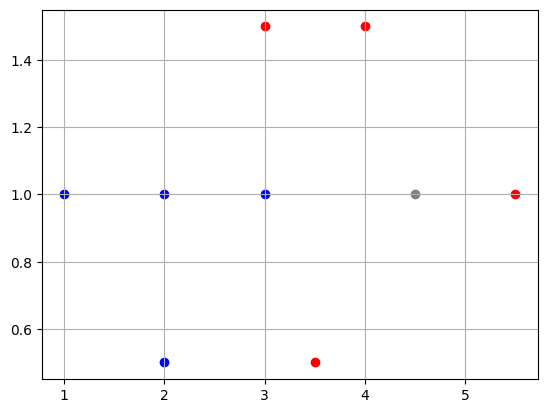

In [3]:
# scatter plot them
def vis_data():
    plt.grid()

    for i in range(len(data)):
        c = 'r'
        if data[i][2] == 0:
            c = 'b'
        plt.scatter([data[i][0]], [data[i][1]], c=c)

    plt.scatter([mystery_flower[0]], [mystery_flower[1]], c='gray')

vis_data()

In [4]:
# network

#       o  flower type
#      / \  w1, w2, b
#     o   o  length, width

In [5]:
# activation function

def sigmoid(x):
    return 1/(1+np.exp(-x))

def sigmoid_p(x):
    return sigmoid(x) * (1-sigmoid(x))

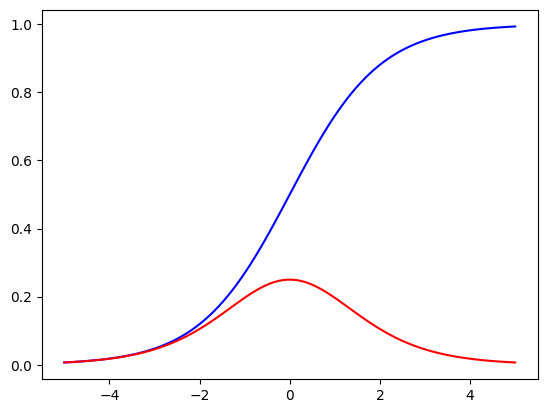

In [6]:
X = np.linspace(-5, 5, 100)

plt.plot(X, sigmoid(X), c="b") # sigmoid in blue
fig = plt.plot(X, sigmoid_p(X), c="r") # sigmoid_p in red

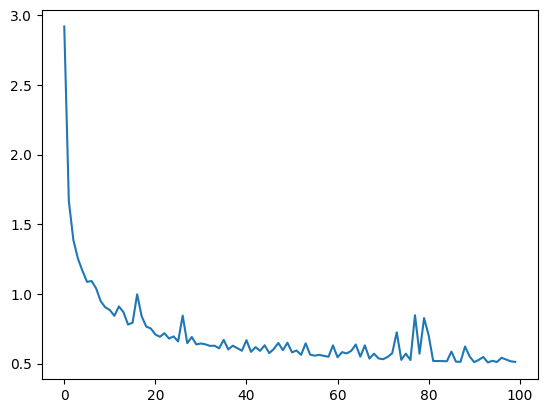

In [7]:
# train

def train():
    #random init of weights
    w1 = np.random.randn()
    w2 = np.random.randn()
    b = np.random.randn()

    iterations = 10000
    learning_rate = 0.1
    costs = [] # keep costs during training, see if they go down

    for i in range(iterations):
        # get a random point
        ri = np.random.randint(len(data))
        point = data[ri]

        z = point[0] * w1 + point[1] * w2 + b
        pred = sigmoid(z) # networks prediction

        target = point[2]

        # cost for current random point
        cost = np.square(pred - target)

        # print the cost over all data points every 1k iters
        if i % 100 == 0:
            c = 0
            for j in range(len(data)):
                p = data[j]
                p_pred = sigmoid(w1 * p[0] + w2 * p[1] + b)
                c += np.square(p_pred - p[2])
            costs.append(c)

        dcost_dpred = 2 * (pred - target)
        dpred_dz = sigmoid_p(z)

        dz_dw1 = point[0]
        dz_dw2 = point[1]
        dz_db = 1

        dcost_dz = dcost_dpred * dpred_dz

        dcost_dw1 = dcost_dz * dz_dw1
        dcost_dw2 = dcost_dz * dz_dw2
        dcost_db = dcost_dz * dz_db

        w1 = w1 - learning_rate * dcost_dw1
        w2 = w2 - learning_rate * dcost_dw2
        b = b - learning_rate * dcost_db

    return costs, w1, w2, b

costs, w1, w2, b = train()

fig = plt.plot(costs)

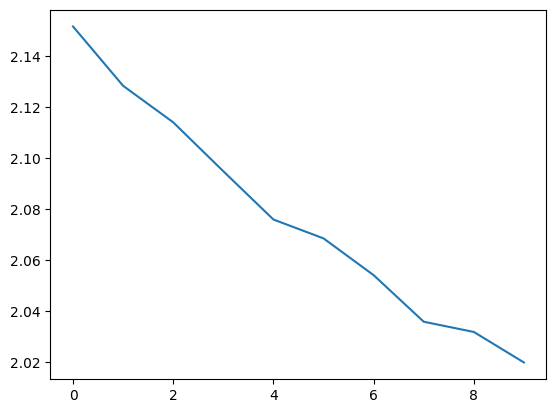

In [11]:
# train

def train():
    #random init of weights
    w1 = np.random.randn()
    w2 = np.random.randn()
    b = np.random.randn()

    iterations = 1000
    learning_rate = 0.001
    costs = [] # keep costs during training, see if they go down

    for i in range(iterations):
        # get a random point
        ri = np.random.randint(len(data))
        point = data[ri]

        z = point[0] * w1 + point[1] * w2 + b
        pred = sigmoid(z) # networks prediction

        target = point[2]

        # cost for current random point
        cost = np.square(pred - target)

        # print the cost over all data points every 1k iters
        if i % 100 == 0:
            c = 0
            for j in range(len(data)):
                p = data[j]
                p_pred = sigmoid(w1 * p[0] + w2 * p[1] + b)
                c += np.square(p_pred - p[2])
            costs.append(c)

        dcost_dpred = 2 * (pred - target)
        dpred_dz = sigmoid_p(z)

        dz_dw1 = point[0]
        dz_dw2 = point[1]
        dz_db = 1

        dcost_dz = dcost_dpred * dpred_dz

        dcost_dw1 = dcost_dz * dz_dw1
        dcost_dw2 = dcost_dz * dz_dw2
        dcost_db = dcost_dz * dz_db

        w1 = w1 - learning_rate * dcost_dw1
        w2 = w2 - learning_rate * dcost_dw2
        b = b - learning_rate * dcost_db

    return costs, w1, w2, b

costs, w1, w2, b = train()

fig = plt.plot(costs)

In [8]:
# predict what the myster flower is!

z = w1 * mystery_flower[0] + w2 * mystery_flower[1] + b
pred = sigmoid(z)

print(pred)
print("close to 0 -> blue, close to 1 -> red")

0.979110248757797
close to 0 -> blue, close to 1 -> red


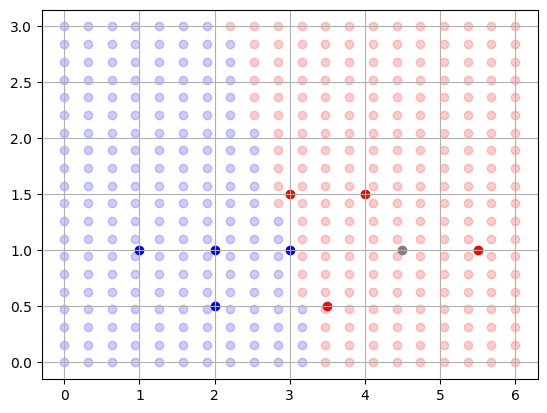

In [9]:
# check out the networks predictions in the x,y plane
for x in np.linspace(0, 6, 20):
    for y in np.linspace(0, 3, 20):
        pred = sigmoid(w1 * x + w2 * y + b)
        c = 'b'
        if pred > .5:
            c = 'r'
        plt.scatter([x],[y],c=c, alpha=.2)

# plot points over network predictions
# you should see a split, with half the predictions blue
# and the other half red.. nicely predicting each data point!
vis_data()

In [15]:
import re

sentences = [
    "Hello world! This is a simple sentence.",
    "Tokenization splits text into individual words.",
    "Let's clean and tokenize these sentences!"
]

def tokenize(text_list):
    words = []
    for sentence in text_list:
        # Lowercase and remove basic punctuation using regex
        cleaned = re.sub(r'[^\w\s]', '', sentence.lower())
        # Split by whitespace
        words.extend(cleaned.split())
    return words

tokens = tokenize(sentences)
print("Original sentences:", sentences)
print("Tokenized words:", tokens)

Original sentences: ['Hello world! This is a simple sentence.', 'Tokenization splits text into individual words.', "Let's clean and tokenize these sentences!"]
Tokenized words: ['hello', 'world', 'this', 'is', 'a', 'simple', 'sentence', 'tokenization', 'splits', 'text', 'into', 'individual', 'words', 'lets', 'clean', 'and', 'tokenize', 'these', 'sentences']


In [16]:
unique_words = sorted(list(set(tokens)))
vocabulary_to_id = {word: idx for idx, word in enumerate(unique_words)}

print("Vocabulary size:", len(vocabulary_to_id))
print("Word to ID mapping:")
for word, idx in list(vocabulary_to_id.items())[:10]:
    print(f"  {word}: {idx}")
if len(vocabulary_to_id) > 10:
    print("  ...")

Vocabulary size: 19
Word to ID mapping:
  a: 0
  and: 1
  clean: 2
  hello: 3
  individual: 4
  into: 5
  is: 6
  lets: 7
  sentence: 8
  sentences: 9
  ...


In [17]:
import numpy as np

vocab_size = len(vocabulary_to_id)
one_hot_vectors = {}

for word, idx in vocabulary_to_id.items():
    # Create a vector of zeros
    vector = np.zeros(vocab_size, dtype=int)
    # Set the element at index 'idx' to 1
    vector[idx] = 1
    one_hot_vectors[word] = vector

# Display a few examples
print(f"Vocabulary Size: {vocab_size}\n")
print("Example One-Hot Vectors:")
for word in list(one_hot_vectors.keys())[:5]:
    print(f"  {word:12}: {one_hot_vectors[word].tolist()}")

Vocabulary Size: 19

Example One-Hot Vectors:
  a           : [1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
  and         : [0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
  clean       : [0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
  hello       : [0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
  individual  : [0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


In [19]:
s1=["new york time angeles"]
s2=["loss angeles times"]


In [21]:
import re
import numpy as np

# Define the input sentences locally to avoid NameError
s1 = ["new york time angeles"]
s2 = ["loss angeles times"]

# Helper to tokenize sentence lists
def basic_tokenize(sentences_list):
    tokens_list = []
    for s in sentences_list:
        cleaned = re.sub(r'[^\w\s]', '', s.lower())
        tokens_list.extend(cleaned.split())
    return tokens_list

# Tokenize both sentence collections
tokens_s1 = basic_tokenize(s1)
tokens_s2 = basic_tokenize(s2)

# Build a unified vocabulary
new_vocab = sorted(list(set(tokens_s1 + tokens_s2)))
word_to_idx = {word: idx for idx, word in enumerate(new_vocab)}

# Create Bag-of-Words vectors for s1 and s2
def get_bow_vector(tokens, vocab_dict):
    vector = np.zeros(len(vocab_dict), dtype=int)
    for token in tokens:
        if token in vocab_dict:
            vector[vocab_dict[token]] += 1
    return vector

vector_s1 = get_bow_vector(tokens_s1, word_to_idx)
vector_s2 = get_bow_vector(tokens_s2, word_to_idx)

print("Unified Vocabulary:", new_vocab)
print("Vector for s1:", vector_s1.tolist())
print("Vector for s2:", vector_s2.tolist())

Unified Vocabulary: ['angeles', 'loss', 'new', 'time', 'times', 'york']
Vector for s1: [1, 0, 1, 1, 0, 1]
Vector for s2: [1, 1, 0, 0, 1, 0]


Decision Boundary Equation: y = -0.0594x + 0.1947


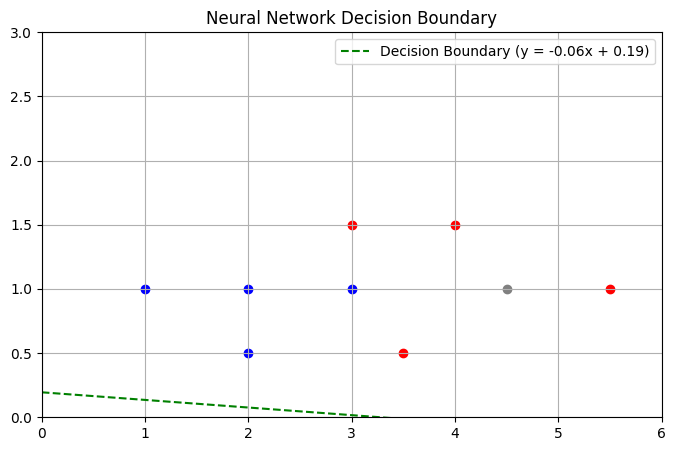

In [22]:
# Calculate slope (m) and intercept (c) from the weights
m = -w1 / w2
c = -b / w2

print(f"Decision Boundary Equation: y = {m:.4f}x + {c:.4f}")

# Plot the decision boundary line
plt.figure(figsize=(8, 5))
vis_data()  # Scatter plot existing flowers and the mystery flower

x_vals = np.linspace(0, 6, 100)
y_vals = m * x_vals + c
plt.plot(x_vals, y_vals, label=f'Decision Boundary (y = {m:.2f}x + {c:.2f})', color='green', linestyle='--')

plt.xlim(0, 6)
plt.ylim(0, 3)
plt.legend()
plt.title("Neural Network Decision Boundary")
plt.show()

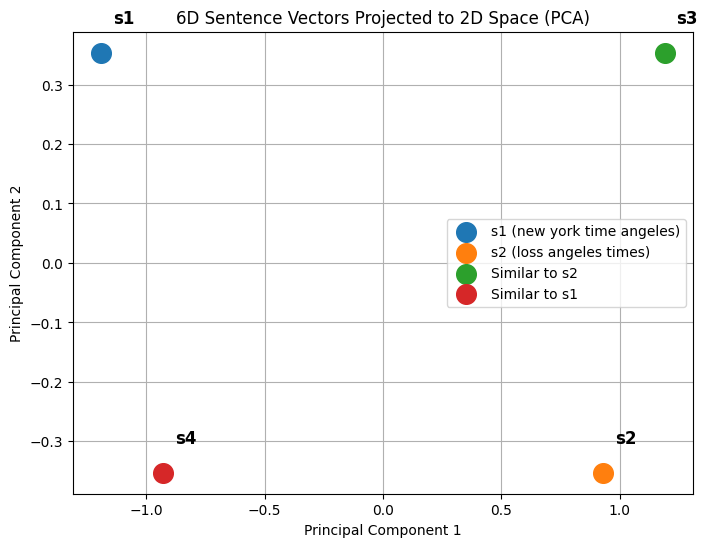

In [24]:
from sklearn.decomposition import PCA
import pandas as pd

# Combine our sentence vectors into a matrix
# We will also add a couple of other test vectors to make the PCA projection more interesting
vectors = np.array([
    vector_s1,
    vector_s2,
    [0, 1, 0, 0, 1, 0], # s3: similar to s2
    [1, 0, 1, 0, 0, 1]  # s4: similar to s1
])

labels = ['s1 (new york time angeles)', 's2 (loss angeles times)', 'Similar to s2', 'Similar to s1']

# Initialize PCA to reduce from 6 dimensions down to 2 dimensions
pca = PCA(n_components=2)
vectors_2d = pca.fit_transform(vectors)

# Create a plot
plt.figure(figsize=(8, 6))
plt.grid(True)

# Plot the coordinates
for i, label in enumerate(labels):
    x, y = vectors_2d[i, 0], vectors_2d[i, 1]
    plt.scatter(x, y, s=200, label=label)
    plt.text(x + 0.05, y + 0.05, f"s{i+1}", fontsize=12, weight='bold')

plt.title("6D Sentence Vectors Projected to 2D Space (PCA)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend()
plt.show()

In [25]:
import numpy as np

# Our 6 vocabulary words mapped to indices:
# {'angeles': 0, 'loss': 1, 'new': 2, 'time': 3, 'times': 4, 'york': 5}
# s1 tokens: ['new', 'york', 'time', 'angeles'] -> Indices: [2, 5, 3, 0]

s1_indices = [word_to_idx[token] for token in tokens_s1]

# 1. Define the lookup function h(indices) which returns the one-hot vectors for each index
def h(indices, vocab_size=6):
    lookup_vectors = []
    for idx in indices:
        one_hot = np.zeros(vocab_size)
        one_hot[idx] = 1.0
        lookup_vectors.append(one_hot)
    return np.array(lookup_vectors) # returns matrix of shape (len(indices), vocab_size)

# 2. Initialize a weight matrix w (e.g., projecting 6 dimensions down to 3 hidden dimensions)
np.random.seed(42)
hidden_dim = 3
w = np.random.randn(len(word_to_idx), hidden_dim)

# 3. Retrieve the lookup representation for s1
h_s1 = h(s1_indices)

# 4. Compute the linear transformation: s = h * w
s_s1 = np.dot(h_s1, w)

print("s1 Token Indices:", s1_indices)
print("\nLookup Matrix h(s1) [One-Hot Representations]:\n", h_s1)
print("\nWeight Matrix w:\n", w)
print("\nFinal Output Layer s = h * w:\n", s_s1)

s1 Token Indices: [2, 5, 3, 0]

Lookup Matrix h(s1) [One-Hot Representations]:
 [[0. 0. 1. 0. 0. 0.]
 [0. 0. 0. 0. 0. 1.]
 [0. 0. 0. 1. 0. 0.]
 [1. 0. 0. 0. 0. 0.]]

Weight Matrix w:
 [[ 0.49671415 -0.1382643   0.64768854]
 [ 1.52302986 -0.23415337 -0.23413696]
 [ 1.57921282  0.76743473 -0.46947439]
 [ 0.54256004 -0.46341769 -0.46572975]
 [ 0.24196227 -1.91328024 -1.72491783]
 [-0.56228753 -1.01283112  0.31424733]]

Final Output Layer s = h * w:
 [[ 1.57921282  0.76743473 -0.46947439]
 [-0.56228753 -1.01283112  0.31424733]
 [ 0.54256004 -0.46341769 -0.46572975]
 [ 0.49671415 -0.1382643   0.64768854]]


In [26]:
def cross_entropy_loss(y_pred, y_true):
    # Clip values to avoid log(0) which results in NaN
    y_pred = np.clip(y_pred, 1e-15, 1 - 1e-15)
    return -np.mean(y_true * np.log(y_pred) + (1 - y_true) * np.log(1 - y_pred))

# Example target label for our sentence s1 classification (e.g., Target class: 1)
target_s1 = np.array([1.0])

# Let's say we averaged our word representations s_s1 and passed them through a sigmoid to get a single probability
pool_representation = np.mean(s_s1, axis=0)
sigmoid_pred = sigmoid(np.mean(pool_representation))

loss_s1 = cross_entropy_loss(sigmoid_pred, target_s1)
print(f"Predicted Probability: {sigmoid_pred:.4f}")
print(f"Target Label: {target_s1[0]}")
print(f"Cross-Entropy Loss: {loss_s1:.4f}")

Predicted Probability: 0.5257
Target Label: 1.0
Cross-Entropy Loss: 0.6430
